In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

In [2]:
sim = AerSimulator()
shots = 100

In [3]:
# Circuit A: X gate
qc_a = QuantumCircuit(1, 1)
qc_a.x(0)
qc_a.measure(0, 0)

# Circuit B: two X gates
qc_b = QuantumCircuit(1, 1)
qc_b.x(0)
qc_b.x(0)
qc_b.measure(0, 0)

# Circuit C: H gate
qc_c = QuantumCircuit(1, 1)
qc_c.h(0)
qc_c.measure(0, 0)

Circuit A


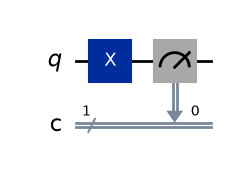

Circuit B


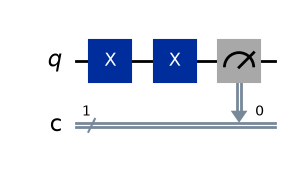

Circuit C


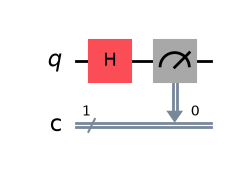

In [4]:
print("Circuit A"); display(qc_a.draw('mpl'))
print("Circuit B"); display(qc_b.draw('mpl'))
print("Circuit C"); display(qc_c.draw('mpl'))

In [5]:
result_a = sim.run(qc_a, shots=shots).result()
result_b = sim.run(qc_b, shots=shots).result()
result_c = sim.run(qc_c, shots=shots).result()

counts_a = result_a.get_counts()
counts_b = result_b.get_counts()
counts_c = result_c.get_counts()

In [6]:
print("Circuit A counts:", counts_a)
print("Circuit B counts:", counts_b)
print("Circuit C counts:", counts_c)

Circuit A counts: {'1': 100}
Circuit B counts: {'0': 100}
Circuit C counts: {'0': 52, '1': 48}


In [7]:
plot_histogram(counts_a, title="Circuit A: X gate")
plot_histogram(counts_b, title="Circuit B: X, X gates")
plot_histogram(counts_c, title="Circuit C: H gate")
plt.show()

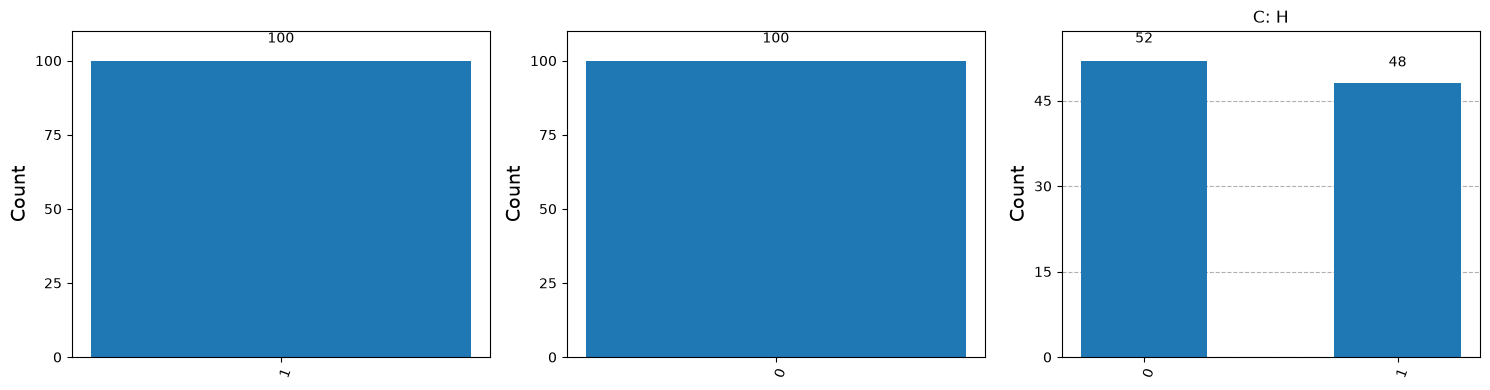

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_histogram(counts_a, ax=axes[0], title="A: X")
plot_histogram(counts_b, ax=axes[1], title="B: X, X")
plot_histogram(counts_c, ax=axes[2], title="C: H")
plt.tight_layout()
plt.show()

In [9]:
for i in range(3):
    print(f"Run {i+1}:", sim.run(qc_c, shots=100).result().get_counts())

Run 1: {'0': 57, '1': 43}
Run 2: {'0': 51, '1': 49}
Run 3: {'1': 51, '0': 49}
